# What drives the mouse's choices during training: the stimulus, a bias, or the last trial?
Oct 2026 \
author: Inês Laranjeira (drafted with Claude)

**Motivation.** In `2_epoch_structure_wheel.ipynb`, fast, middle and slow learners looked surprisingly
similar in *when* they move the wheel. The one clear difference was after errors: fast learners keep
pausing after mistakes for longer. What has to change for a mouse to learn is how its **choices**
depend on the stimulus. So this notebook asks what else drives choices over training, and whether
that differs with learning speed. It is **step 1**: per-session measures and their trajectories.
There are no tests yet.

**Data.** Trial tables only: every pre-proficiency training session of all 102 mice (1,923 sessions).
No wheel or video data is needed, so every mouse has every session.

**Measures** (`choice_strategy.py`, one row per session). Choices are in **stimulus coordinates**:
side +1 is the response that is correct for a right-side stimulus. This does not rely on the `choice`
labels, and the mapping is checked below.
* **Accuracy** on easy trials (contrast ≥ 0.5), and the share of no-go trials.
* **Side bias:** P(choose +1) averaged over the two stimulus sides, minus 0.5. Averaging over sides
  keeps the protocol's stimulus placement (below) from leaking into the bias. |bias| measures how
  one-sided the mouse is.
* **Choice model,** a logistic regression per session:
  logit P(+1) = b0 + w_stim · signed contrast + w_win · previous side · [previous correct]
  + w_lose · previous side · [previous error].
  * **w_stim:** how strongly the stimulus drives the choice.
  * **w_win > 0:** repeats a rewarded choice beyond what the stimulus explains.
  * **w_lose > 0:** repeats a choice that was just wrong; **< 0:** switches after errors.
* **Raw stay probabilities** after correct and after error trials, for reference.
* **Post-error adjustments:** accuracy after an error vs after a correct trial, and log(median reaction
  time after error / after correct), i.e. post-error slowing.
* **The wheel post-error pause** from notebook 2: log(free-window movement rate after error / after
  correct). This is only available for the sessions with wheel data.

**Learning speed:** sessions until the third contrast is added (`LS_DEF`, as in notebook 2; higher =
slower). Mice are split into thirds.

In [1]:
import sys, pathlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = pathlib.Path.cwd()
sys.path.insert(0, str(HERE.parent / 'paper-individuality'))
import paper_style as ps
ps.use('paper')
import epoch_structure as es
import choice_strategy as cs

LS_DEF = 'third_contrast'          # or 'proficiency'

S = cs.build()                     # cached; cs.build(refresh=True) recomputes (~20 s)
LS = es.learning_speed(LS_DEF)
S3 = es.sessions_to_third_contrast(verbose=False)
S['log_train'] = S['mouse_name'].map(LS)
S['rel_3c'] = S['session_index'] - S['mouse_name'].map(S3)
S['is_training_protocol'] = S['protocol'].str.contains('training')
C = S[S['log_train'].notna() & S['is_training_protocol']].copy()
terc = pd.qcut(C.drop_duplicates('mouse_name').set_index('mouse_name')['log_train'], 3,
               labels=['fast', 'middle', 'slow'])
C['tercile'] = C['mouse_name'].map(terc)
T_COL = {'fast': '#2166AC', 'middle': '#8C8C8C', 'slow': '#B2182B'}
NBIN = 10
C['frac_bin'] = np.minimum((C['training_fraction'] * NBIN).astype(int), NBIN - 1)

# wheel post-error pause from notebook 2 (sessions with wheel data only)
SW = es.build()
FW = es.build_feedback(SW).pivot_table(index='session', columns='prev', values='free_matched_rate')
C['wheel_post_error_pause'] = C['session'].map(np.log(FW['error'] / FW['correct']).replace([np.inf, -np.inf], np.nan))
C['acc_post_error_diff'] = C['acc_after_error'] - C['acc_after_correct']

print(f"{len(C)} sessions, {C.mouse_name.nunique()} mice "
      f"({(~S['is_training_protocol']).sum()} biasedChoiceWorld sessions dropped; "
      f"{S['log_train'].isna().groupby(S.mouse_name).first().sum()} mice without a learning-speed value)")
print(C.drop_duplicates('mouse_name').assign(s3=lambda d: d.mouse_name.map(S3))
      .groupby('tercile', observed=True)[['s3', 'n_sessions_total']].agg(['count', 'min', 'median', 'max']).to_string())

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


third contrast: 2 left-censored ['DY_010', 'PL034'], 1 never reach it ['SWC_065']


1901 sessions, 99 mice (2 biasedChoiceWorld sessions dropped; 3 mice without a learning-speed value)
           s3                    n_sessions_total               
        count   min median   max            count min median max
tercile                                                         
fast       34   2.0    6.0   7.0               34   4   10.0  38
middle     36   8.0   11.0  12.0               36   9   16.0  41
slow       29  13.0   17.0  40.0               29  13   27.0  58


/opt/anaconda3/envs/iblenv/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


## Sanity checks

**1. Side convention.** On correct trials, the chosen side (−`choice`) must equal the stimulus side.

**2. Where the protocol puts the stimulus after an error.** trainingChoiceWorld does not simply repeat
the stimulus side after an error. The check below conditions on the mouse's **recent bias** (mean side
of its last 10 choices) and asks how often the stimulus lands on the same side as on the error trial.
If placement depends on that bias, the protocol is *debiasing*: it puts the stimulus on the side the
mouse has been avoiding.

In [2]:
rows = []
for f in sorted(os.listdir(es.TRIALS_DIR)):
    t = cs.prepare(es.mouse_trials(f.replace('training_data_trials_', '')))
    t['recent_bias'] = t.groupby('session_index')['side'].transform(
        lambda x: x.where(x != 0).shift().rolling(10, min_periods=5).mean())
    rows.append(t[['correct', 'stim', 'side', 'prev_stim', 'prev_correct', 'prev_signed_contrast',
                   'recent_bias', 'task_protocol']])
T = pd.concat(rows, ignore_index=True)

ok = (T.correct == 1) & (T.stim != 0) & (T.side != 0)
print(f'side == stim on correct trials: {np.mean(T.side[ok] == T.stim[ok]):.4f}  ({ok.sum()} trials)')

e = T[(T.prev_correct == 0) & (T.prev_signed_contrast.abs() >= 0.5) & (T.stim != 0) & T.recent_bias.notna()].copy()
e['same_side'] = e.stim == e.prev_stim
c = T[(T.prev_correct == 1) & (T.stim != 0) & T.recent_bias.notna()].copy()
c['same_side'] = c.stim == c.prev_stim
bins = [-1.01, -0.6, -0.2, 0.2, 0.6, 1.0]
lab = ['strong −', 'weak −', 'none', 'weak +', 'strong +']
tab = pd.DataFrame({
    'after easy error: P(same side)': e.groupby(pd.cut(e.recent_bias, bins, labels=lab), observed=True)['same_side'].mean(),
    'after easy error: P(stim = +1)': e.groupby(pd.cut(e.recent_bias, bins, labels=lab), observed=True)['stim'].apply(lambda s: (s > 0).mean()),
    'after correct: P(stim = +1)': c.groupby(pd.cut(c.recent_bias, bins, labels=lab), observed=True)['stim'].apply(lambda s: (s > 0).mean()),
    'n (after error)': e.groupby(pd.cut(e.recent_bias, bins, labels=lab), observed=True).size()})
tab.index.name = 'recent bias (last 10 choices)'
print(f'\nafter an easy error, overall P(same side) = {e.same_side.mean():.3f}; '
      f'P(stimulus opposite the recent bias) = {(e.stim == -np.sign(e.recent_bias))[e.recent_bias != 0].mean():.3f}')
tab.round(3)

side == stim on correct trials: 1.0000  (747827 trials)



after an easy error, overall P(same side) = 0.653; P(stimulus opposite the recent bias) = 0.698


,after easy error: P(same side),after easy error: P(stim = +1),after correct: P(stim = +1),n (after error)
recent bias (last 10 choices),,,,
strong −,0.759,0.772,0.610,76806
weak −,0.560,0.607,0.530,57299
none,0.516,0.460,0.492,55997
weak +,0.642,0.319,0.449,50895
strong +,0.792,0.202,0.362,38648


**Reading.** After an easy error the stimulus side repeats about 65% of the time overall, but that
number depends strongly on the mouse's recent bias:
* ≈ 76–79% when the mouse has been choosing one side strongly;
* ≈ 52% when it has no recent bias.

The stimulus is placed **opposite the side the mouse has been choosing**. After a correct trial the
same push is present but weaker. So "the side repeats after an error" is true mostly for biased mice,
which early in training is most of them.

Two consequences for the choice measures:
1. **A stimulus-blind strategy is partly rewarded.** "Switch away from the side I have been
   choosing" (anti-bias, or lose-shift) earns reward without using the stimulus. Separating stimulus
   use from history therefore needs the stimulus in the model, which `w_stim` provides.
2. **The protocol's placement depends on the mouse's own behaviour.** A biased mouse sees a different
   stimulus sequence from an unbiased one. Stimulus statistics are therefore not identical across mice
   or sessions, and protocol versions differ too (one version, 6.6.1, almost never repeats).

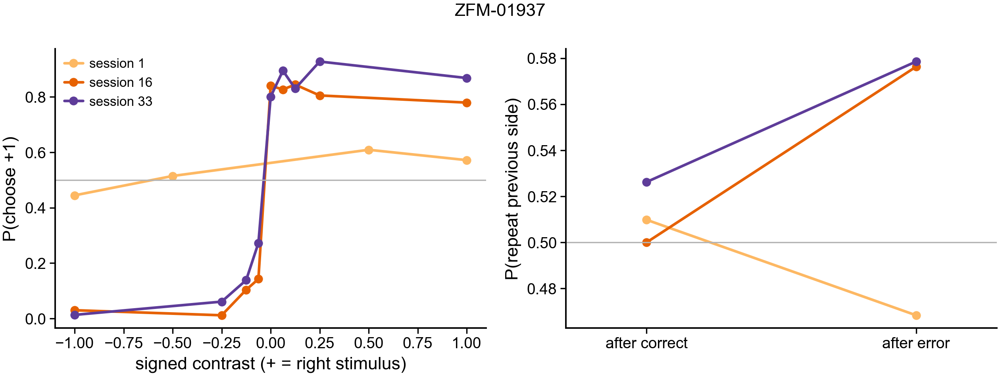

 session_index  accuracy_easy  bias  w_stim  w_win  w_lose
             1           0.56  0.03    0.31   0.03   -0.14
            17           0.85  0.05    2.20   0.51    0.06
            33           0.92 -0.00    5.46   0.09    0.28


In [3]:
# one example session: psychometric curve and the history effects, early vs late
ex = C.drop_duplicates('mouse_name').sort_values('log_train').iloc[len(terc) // 2]['mouse_name']
t = cs.prepare(es.mouse_trials(ex))
n_ex = t.session_index.max()
fig, axs = plt.subplots(1, 2, figsize=(6.5, 2.5))
for si, col in [(1, '#FDB863'), (max(2, n_ex // 2), '#E66101'), (n_ex, '#5E3C99')]:
    g = t[(t.session_index == si) & (t.side != 0)]
    p = g.groupby('signed_contrast')['side'].apply(lambda s: (s > 0).mean())
    axs[0].plot(p.index, p.values, 'o-', color=col, ms=3, label=f'session {si}')
    v = g[g.prev_side.isin([-1, 1])]
    st = [(v.side == v.prev_side)[v.prev_correct == k].mean() for k in (1, 0)]
    axs[1].plot([0, 1], st, 'o-', color=col, ms=3)
axs[0].set_xlabel('signed contrast (+ = right stimulus)'); axs[0].set_ylabel('P(choose +1)')
axs[0].axhline(0.5, color='0.7', lw=0.6); axs[0].legend(fontsize=6, frameon=False)
axs[1].set_xticks([0, 1]); axs[1].set_xticklabels(['after correct', 'after error']); axs[1].set_xlim(-0.3, 1.3)
axs[1].axhline(0.5, color='0.7', lw=0.6); axs[1].set_ylabel('P(repeat previous side)')
fig.suptitle(ex, fontsize=8)
plt.tight_layout(); plt.show()
print(C.loc[C.mouse_name == ex, ['session_index', 'accuracy_easy', 'bias', 'w_stim', 'w_win', 'w_lose']]
      .iloc[[0, len(C[C.mouse_name == ex]) // 2, -1]].round(2).to_string(index=False))

## Trajectories over training

Same layout as notebook 2: thin lines are individual mice, thick lines are learning-speed medians.
* **Left:** by session number. The right-hand end is slow learners only.
* **Middle:** by fraction of training (10 bins).
* **Right:** aligned to the third-contrast session (0). Medians are drawn where at least 4 mice
  contribute.

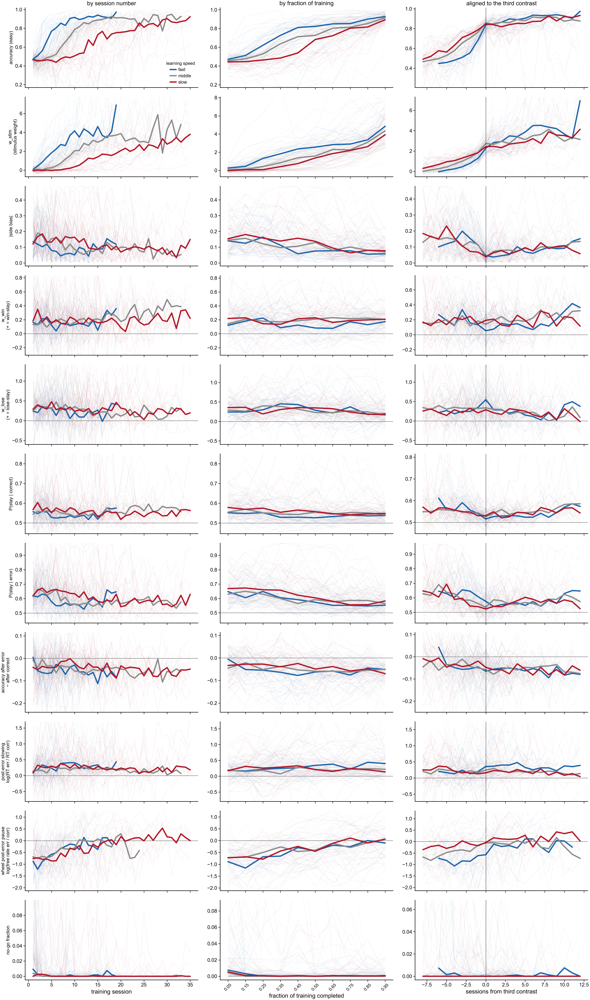

In [4]:
MEASURES = [('accuracy_easy', 'accuracy (easy)'),
            ('w_stim', 'w_stim\n(stimulus weight)'),
            ('abs_bias', '|side bias|'),
            ('w_win', 'w_win\n(+ = win-stay)'),
            ('w_lose', 'w_lose\n(+ = lose-stay)'),
            ('p_stay_after_correct', 'P(stay | correct)'),
            ('p_stay_after_error', 'P(stay | error)'),
            ('acc_post_error_diff', 'accuracy after error\n− after correct'),
            ('post_error_rt_logratio', 'post-error slowing\nlog(RT err / RT corr)'),
            ('wheel_post_error_pause', 'wheel post-error pause\nlog(free rate err / corr)'),
            ('nogo_frac', 'no-go fraction')]
ZERO = {'w_win', 'w_lose', 'acc_post_error_diff', 'post_error_rt_logratio', 'wheel_post_error_pause'}
HALF = {'p_stay_after_correct', 'p_stay_after_error'}
MAX_SESS, REL = 35, (-8, 12)

fig, axs = plt.subplots(len(MEASURES), 3, figsize=(11.5, 1.75 * len(MEASURES)), sharex='col')
for i, (col, lbl) in enumerate(MEASURES):
    for j, xcol in enumerate(['session_index', 'frac_bin', 'rel_3c']):
        ax = axs[i, j]
        d = (C[C.session_index <= MAX_SESS] if j == 0 else C if j == 1 else C[C.rel_3c.between(*REL)])
        d = d[d[col].notna()]
        for m, g in d.groupby('mouse_name'):
            gg = g.groupby(xcol)[col].mean()
            ax.plot(gg.index, gg.values, color=T_COL[g['tercile'].iloc[0]], alpha=0.08, lw=0.5)
        for tc, c_ in T_COL.items():
            gm = d[d.tercile == tc].groupby(['mouse_name', xcol])[col].mean().groupby(xcol)
            med, n = gm.median(), gm.size()
            ax.plot(med[n >= 4].index, med[n >= 4].values, color=c_, lw=1.8, label=tc)
        lo, hi = d[col].quantile([0.02, 0.98])
        ax.set_ylim(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo))
        if col in ZERO:
            ps.zero_line(ax)
        if col in HALF:
            ax.axhline(0.5, color='k', lw=0.5, alpha=0.6)
        if j == 2:
            ax.axvline(0, color='k', lw=0.6, alpha=0.6)
        if j == 0:
            ax.set_ylabel(lbl, fontsize=6.5)
axs[0, 0].legend(fontsize=6, frameon=False, title='learning speed', title_fontsize=6)
axs[-1, 0].set_xlabel('training session')
axs[-1, 1].set_xlabel('fraction of training completed')
axs[-1, 1].set_xticks(range(NBIN)); axs[-1, 1].set_xticklabels([f'{(k + .5) / NBIN:.2f}' for k in range(NBIN)],
                                                              rotation=45, fontsize=6)
axs[-1, 2].set_xlabel('sessions from third contrast')
for j, ttl in enumerate(['by session number', 'by fraction of training', 'aligned to the third contrast']):
    axs[0, j].set_title(ttl, fontsize=8)
plt.tight_layout(); plt.show()

### In numbers

Median per learning-speed third, over each mouse's sessions in three windows aligned to the third
contrast:
* **well before:** 6 to 3 sessions before;
* **just before:** 2 sessions before to the third-contrast session itself;
* **after:** 1 to 4 sessions after.

The first window only includes mice that have sessions that early, so it under-represents fast learners.

In [5]:
win = pd.cut(C['rel_3c'], [-6.5, -2.5, 0.5, 4.5], labels=['well before (−6..−3)', 'just before (−2..0)', 'after (+1..+4)'])
cols = [m for m, _ in MEASURES]
tab = (C.assign(win=win).dropna(subset=['win'])
       .groupby(['tercile', 'win', 'mouse_name'], observed=True)[cols].mean()
       .groupby(['tercile', 'win'], observed=True).agg(['median']).droplevel(1, axis=1))
tab['n_mice'] = (C.assign(win=win).dropna(subset=['win']).groupby(['tercile', 'win'], observed=True)['mouse_name'].nunique())
tab.round(3).T

tercile                                fast                      \
win                    well before (−6..−3) just before (−2..0)   
accuracy_easy                         0.485               0.703   
w_stim                                0.277               1.428   
abs_bias                              0.156               0.110   
w_win                                 0.227               0.128   
w_lose                                0.241               0.383   
p_stay_after_correct                  0.566               0.542   
p_stay_after_error                    0.636               0.610   
acc_post_error_diff                  -0.025              -0.047   
post_error_rt_logratio                0.233               0.153   
wheel_post_error_pause               -0.947              -0.912   
nogo_frac                             0.009               0.001   
n_mice                               27.000              34.000   

tercile                                             middle  \
win                    after (+1..+4) well before (−6..−3)   
accuracy_easy                   0.885                0.558   
w_stim                          3.581                0.565   
abs_bias                        0.049                0.127   
w_win                           0.148                0.199   
w_lose                          0.228                0.330   
p_stay_after_correct            0.533                0.562   
p_stay_after_error              0.540                0.627   
acc_post_error_diff            -0.052               -0.031   
post_error_rt_logratio          0.341                0.235   
wheel_post_error_pause         -0.102               -0.418   
nogo_frac                       0.001                0.000   
n_mice                         34.000               36.000   

tercile                                                    \
win                    just before (−2..0) after (+1..+4)   
accuracy_easy                        0.762          0.870   
w_stim                               1.989          3.231   
abs_bias                             0.089          0.076   
w_win                                0.154          0.166   
w_lose                               0.373          0.260   
p_stay_after_correct                 0.536          0.539   
p_stay_after_error                   0.565          0.567   
acc_post_error_diff                 -0.052         -0.070   
post_error_rt_logratio               0.206          0.265   
wheel_post_error_pause              -0.142         -0.113   
nogo_frac                            0.000          0.000   
n_mice                              36.000         35.000   

tercile                                slow                                     
win                    well before (−6..−3) just before (−2..0) after (+1..+4)  
accuracy_easy                         0.611               0.777          0.820  
w_stim                                0.958               2.000          2.898  
abs_bias                              0.159               0.064          0.075  
w_win                                 0.228               0.174          0.191  
w_lose                                0.247               0.251          0.235  
p_stay_after_correct                  0.565               0.541          0.535  
p_stay_after_error                    0.622               0.544          0.574  
acc_post_error_diff                  -0.031              -0.034         -0.063  
post_error_rt_logratio                0.264               0.146          0.230  
wheel_post_error_pause               -0.340              -0.253         -0.067  
nogo_frac                             0.001               0.000          0.002  
n_mice                               29.000              29.000         28.000

## Observations (descriptive; no tests yet)

**1. The difference between fast and slow learners is *when* the stimulus starts to drive choices.**
* **Normalised time doesn't hide this one,** unlike the wheel measures in notebook 2. Slow learners spend
  the first ~25–30% of their training with w_stim ≈ 0: their choices ignore the stimulus. Fast learners'
  stimulus weight starts rising almost immediately. Accuracy shows the same lead.
* **By session number:** w_stim stays near 0 for about 6–8 sessions in slow learners, and the rise
  after that also looks shallower.
* **A quick per-mouse check** (not in the cells above). Take "onset" as the first session where w_stim
  averaged over 2 sessions exceeds 1:
  * Onset median: fast 4, middle 8, slow 13 sessions.
  * Sessions from onset to the third contrast: fast 1, middle 2, slow 4.
  * So most of the variation in learning speed sits *before* the stimulus begins to matter
    (onset vs sessions to third contrast: ρ = +0.89; onset-to-criterion: ρ = +0.59).
  * Caveat: both onset and the third-contrast criterion depend on performance, so part of that ρ is
    built in. The split into "before onset" and "after onset", though, is informative.

**2. What choices depend on before the stimulus matters.**
* **Side bias** is higher early (|bias| ≈ 0.15) and falls with learning. Slow learners stay more biased
  for longer in normalised time. But bias in the first 3 sessions does not predict learning speed
  (ρ ≈ 0.03), so it is not a starting trait.
* **Choice history** acts the same in every group. w_win and w_lose are both positive (≈ 0.2–0.3) and
  stable throughout training: mice repeat their previous choice beyond what the stimulus explains, and
  they do so **even after errors**. P(stay | error) ≈ 0.6–0.65 early, above P(stay | correct) ≈ 0.55.
  * This happens even though the protocol places the stimulus against the mouse's bias, so switching
    would usually be correct.
  * Accuracy after an error is ≈ 0.05 lower than after a correct trial, consistent with this.
* **No-go trials** are negligible after the first sessions.

**3. Post-error behaviour.**
* **Post-error slowing** (reaction time) is positive and similar across groups, with fast learners
  slightly higher after the third contrast.
* **The wheel post-error pause** reproduces notebook 2. Fast learners keep pausing after errors in the
  sessions before the third contrast, while slow learners have mostly lost the pause by then. In
  normalised time the groups overlap.

**What this suggests for step 2.** The question shifts from "what differs while they learn" to "what
happens before the stimulus starts to matter".
* **Per mouse:** onset of stimulus use, and the rate of rise after it, estimated with a smooth fit
  across sessions rather than a threshold.
* **Before onset:** what the choices follow instead (bias, perseveration, lose-stay); whether that
  pattern predicts how long the latent phase lasts; and whether early stimulus effects are already
  present in behaviour other than choice, such as reaction times or the wheel post-error pause.
* **Model comparison:** this is close to what the state-discovery agent (M2) in the toy model would
  show. A long phase in which the stimulus is not yet a feature of the state, then a split on it.
  Comparing the shape of the w_stim rise with M1 vs M2 simulations is a natural next step.